# Project: Transaction Data Analytics in Python
### Real dataset: City of Denver Open Checkbook, calendar year 2025

Five data checks run against 152,635 real public-sector payment transactions: Benford's Law (dataset-level
integrity check), round-number check, period-end spending spike, duplicate payment detection, and threshold
clustering (payments just below an approval limit).


In [3]:
import sys
!{sys.executable} -m pip install pandas numpy matplotlib --quiet

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


RAW_PATH = "/Users/DELL/Downloads/City_of_Denver_Checkbook_2025.csv"



## Step 1 — Load & scope the data

`RowId` is the true unique line-item identifier. `PaymentId` groups multiple line items that were
paid together in a single AP payment run — it is **not** a one-row-per-transaction key, so it isn't
used for uniqueness here.

Zero/negative amounts (credits, refunds, reversals) are set aside — they're out of scope for these
five tests, which are designed around genuine spend.

In [4]:
df = pd.read_csv(RAW_PATH, thousands=",")
df["PaymentDate"] = pd.to_datetime(df["PaymentDate"], format="mixed", errors="coerce")

print(f"Raw rows: {len(df):,}")
assert df["RowId"].is_unique, "RowId not unique — re-check the source file"

credits = df[df["Amount"] <= 0]
work = df[df["Amount"] > 0].copy()

print(f"Excluded {len(credits):,} zero/negative-amount rows (credits, refunds, reversals)")
print(f"Working set: {len(work):,} rows")

work["Weekday"] = work["PaymentDate"].dt.day_name()
work["Month"] = work["PaymentDate"].dt.month
work.head()

Raw rows: 154,596
Excluded 1,961 zero/negative-amount rows (credits, refunds, reversals)
Working set: 152,635 rows


,RowId,Payee,City,State,ProgramArea,Department,PaymentId,PaymentDate,Year,Amount,PurchaseOrder,FundingSourceDescription,Project,ProjectDescription,ExpenseCategory,ExpenseSubCategory,Weekday,Month
0,3875635-4730774555614212DEC2024-686360,US BANK NATIONAL ASSOCIATION,MINNEAPOLIS,MN,General Government,Department of Finance,3875635.0,2025-01-02,2025,126609.04,NaN,General Fund,NaN,NaN,P and T Card Suspense,P-card Clearing,Thursday,1
1,3875636-26466-685396,BLUE STAR RECYCLERS,COLORADO SPRINGS,CO,General Government,Department of General Services,3875636.0,2025-01-02,2025,406.33,PO-00143285,General Fund,NaN,NaN,Professional Services,Refuse disposal and treatment,Thursday,1
2,3875636-26473-685443,BLUE STAR RECYCLERS,COLORADO SPRINGS,CO,DOTI,DOTI,3875636.0,2025-01-02,2025,3220.61,PO-00143922,Volume-Based Trash Pricing,NaN,NaN,Professional Services,Refuse disposal and treatment,Thursday,1
3,3875638-OCT24RAPIDRESHOST-686019,COLORADO COALITION FOR THE HOMELESS,DENVER,CO,Community Development,Department of Housing Stability Special,3875638.0,2025-01-02,2025,10611.54,PO-00138994,Homelessness Resolution,NaN,NaN,Professional Services,Community and social services,Thursday,1
4,3875639-INV10167046-685401,MERRICK & COMPANY,GREENWOOD VILLAGE,CO,General Government,Department of Finance,3875639.0,2025-01-02,2025,258.65,PO-00145680,Revenue Projects,PRJ-10005430,National Western Drive South,Professional Services,Professional engineering servi,Thursday,1


## Test 1 — Benford's Law (dataset-level integrity check only)

Naturally occurring numerical data follows a predictable first-digit distribution (digit 1 appears
~30% of the time, down to digit 9 at ~4.6%). Fabricated numbers tend to deviate from this because
people are bad at faking realistic-looking distributions.

Benford's Law is a *distribution-level* test — it tells you whether the dataset as a
whole looks natural, not whether any single transaction is suspect.  Digits 1 and 2 naturally make up
~48% of all data even when everything is clean — that flagged ~44% of the dataset for no real reason.
Hence we will keep Benford as a whole-population sanity check (via Nigrini's MAD and chi-square) and
does **not** feed a flag_benford column into the cross-test overlap count.

Two goodness-of-fit checks are reported, because they can disagree at large sample sizes:
- **Chi-square** — the classic test, but its p-value becomes hypersensitive at high N (tiny, practically
  meaningless deviations become "statistically significant").
- **Nigrini's MAD (Mean Absolute Deviation)** — the standard alternative for large forensic-accounting
  datasets. Boundaries: <0.006 close conformity, 0.006–0.012 acceptable, 0.012–0.015 marginal, >0.015
  nonconformity.

In [5]:
def first_digit(x):
    s = str(abs(x)).lstrip("0.").replace(".", "")
    for ch in s:
        if ch.isdigit() and ch != "0":
            return int(ch)
    return None

work["FirstDigit"] = work["Amount"].apply(first_digit)

benford_expected = {1: 30.1, 2: 17.6, 3: 12.5, 4: 9.7, 5: 7.9, 6: 6.7, 7: 5.8, 8: 5.1, 9: 4.6}
actual_counts = work["FirstDigit"].value_counts().sort_index()
actual_pct = (actual_counts / actual_counts.sum() * 100).round(2)

benford_table = pd.DataFrame({
    "digit": list(range(1, 10)),
    "expected_pct": [benford_expected[d] for d in range(1, 10)],
    "actual_pct": [actual_pct.get(d, 0) for d in range(1, 10)],
})
benford_table["abs_deviation"] = (benford_table["actual_pct"] - benford_table["expected_pct"]).abs()

expected_counts = np.array([benford_expected[d] / 100 * len(work) for d in range(1, 10)])
observed_counts = np.array([actual_counts.get(d, 0) for d in range(1, 10)])
chi_sq = ((observed_counts - expected_counts) ** 2 / expected_counts).sum()

mad = (benford_table["actual_pct"] - benford_table["expected_pct"]).abs().mean() / 100
if mad < 0.006:
    verdict = "Close conformity"
elif mad < 0.012:
    verdict = "Acceptable conformity"
elif mad < 0.015:
    verdict = "Marginally acceptable conformity"
else:
    verdict = "Nonconformity"

print(benford_table.to_string(index=False))
print(f"\nChi-square statistic: {chi_sq:.1f}  (critical value at df=8, p=0.05 is 15.51)")
print(f"Nigrini MAD: {mad:.5f}  -> {verdict}")
print("\nNote: Benford's Law is used here as a dataset-level integrity check only. No individual")
print("transactions are flagged on this basis — see the note above for why.")

 digit  expected_pct  actual_pct  abs_deviation
     1          30.1       31.94           1.84
     2          17.6       17.34           0.26
     3          12.5       12.07           0.43
     4           9.7        9.32           0.38
     5           7.9        8.30           0.40
     6           6.7        6.31           0.39
     7           5.8        5.50           0.30
     8           5.1        4.78           0.32
     9           4.6        4.45           0.15

Chi-square statistic: 350.4  (critical value at df=8, p=0.05 is 15.51)
Nigrini MAD: 0.00497  -> Close conformity

Note: Benford's Law is used here as a dataset-level integrity check only. No individual
transactions are flagged on this basis — see the note above for why.


## Test 2 — Round-number test

Real spend data rarely has more than a small single-digit percentage of exactly round amounts.
A spike is notable. Each row is tagged with the *tightest* round band it falls into (checked from
$5,000 down to $100).

In [6]:
def round_band(amount):
    if amount % 5000 == 0:
        return 5000
    if amount % 1000 == 0:
        return 1000
    if amount % 500 == 0:
        return 500
    if amount % 100 == 0:
        return 100
    return None

work["round_band"] = work["Amount"].apply(round_band)
work["flag_round"] = work["round_band"].notna()

for band in [100, 500, 1000, 5000]:
    n = (work["round_band"] == band).sum()
    print(f"  Exact multiple of {band:>5}: {n:>6,} rows ({n/len(work)*100:.2f}%)")
print(f"  TOTAL flagged (any band): {work['flag_round'].sum():,} rows "
      f"({work['flag_round'].mean()*100:.2f}%)")

  Exact multiple of   100:  4,618 rows (3.03%)
  Exact multiple of   500:  1,408 rows (0.92%)
  Exact multiple of  1000:  1,346 rows (0.88%)
  Exact multiple of  5000:    893 rows (0.59%)
  TOTAL flagged (any band): 8,265 rows (5.41%)


## Test 3

**Data note:** `PaymentDate` is an AP payment-run date, not the underlying purchase/invoice date —
payments cluster on a handful of weekly run-dates with almost zero weekend activity, and exact
time-of-day isn't published at all. So this test is reframed around **fiscal year-end budget
clustering** ("use it or lose it" spending) rather than day/time-of-purchase anomalies, alongside a
(weak, on its own) weekend flag.

In [7]:
work["flag_weekend"] = work["Weekday"].isin(["Saturday", "Sunday"])

dept_monthly = work.groupby(["Department", "Month"])["Amount"].sum().unstack(fill_value=0)
dept_monthly_avg_jan_nov = dept_monthly.loc[:, 1:11].mean(axis=1)
dept_dec_spend = dept_monthly.get(12, pd.Series(0, index=dept_monthly.index))
dept_yearend_ratio = (dept_dec_spend / dept_monthly_avg_jan_nov.replace(0, np.nan)).fillna(0)

yearend_depts = dept_yearend_ratio[dept_yearend_ratio >= 2.0].sort_values(ascending=False)

print(f"Weekend-dated rows: {work['flag_weekend'].sum():,} ({work['flag_weekend'].mean()*100:.3f}%)")
print("\nDepartments where December spend >= 2x their Jan-Nov monthly average:")
print(yearend_depts.round(2).to_string())

work["flag_yearend"] = work["Department"].isin(yearend_depts.index) & (work["Month"] == 12)
work["flag_timing"] = work["flag_weekend"] | work["flag_yearend"]

Weekend-dated rows: 6 (0.004%)

Departments where December spend >= 2x their Jan-Nov monthly average:
Department
Payment Denver Cares                 4.96
DHHA Contract Administration         3.68
Office of the Independent Monitor    3.00
Department of Finance                2.85
Wastewater Management Division       2.77
Payment Public Health Clinic         2.68


## Test 4: Duplicate payment test

**Data note:** a single `PaymentId` can bundle many *legitimate* line items paid together in one
batch (same payee, same amount, repeated because they're separate invoice lines for identical
items). A true duplicate payment is the same Payee + Amount + ExpenseCategory
occurring across **different** payment runs within a short window — i.e. paid twice, separately.

The logic: sort by Payee/Amount/ExpenseCategory/Date, then compare each row to the *previous* row
in the same group using `.shift(1)`, and only flag it if that previous row belonged to a different
`PaymentId`.

Written as a function of the window size so it can be re-run for the robustness check further down.

In [8]:
def flag_duplicates(data, window_days):
    sorted_df = data.sort_values(["Payee", "Amount", "ExpenseCategory", "PaymentDate"]).copy()
    sorted_df["prev_date"] = sorted_df.groupby(["Payee", "Amount", "ExpenseCategory"])["PaymentDate"].shift(1)
    sorted_df["prev_paymentid"] = sorted_df.groupby(["Payee", "Amount", "ExpenseCategory"])["PaymentId"].shift(1)
    sorted_df["days_since_prev"] = (sorted_df["PaymentDate"] - sorted_df["prev_date"]).dt.days

    is_dup = (
        (sorted_df["days_since_prev"] <= window_days)
        & (sorted_df["days_since_prev"] >= 0)
        & (sorted_df["prev_paymentid"] != sorted_df["PaymentId"])
    )
    sorted_df["flag_duplicate"] = is_dup
    return sorted_df[["RowId", "flag_duplicate"]]

DUP_WINDOW_DAYS = 30
dup_flags = flag_duplicates(work, DUP_WINDOW_DAYS)
work = work.merge(dup_flags, on="RowId", how="left")
work["flag_duplicate"] = work["flag_duplicate"].fillna(False)

print(f"Flagged: {work['flag_duplicate'].sum():,} rows ({work['flag_duplicate'].mean()*100:.3f}%) "
      f"— same payee+amount+category, different payment run, within {DUP_WINDOW_DAYS} days")

Flagged: 14,595 rows (9.562%) — same payee+amount+category, different payment run, within 30 days


## Test 5 — Threshold clustering test

**Sourced threshold** (not an assumption): the City and County of Denver General Services Purchasing Procurement Policy and Procedure Manual defines a purchase made without a valid procurement mechanism as a "Fiscal Rule Violation" under $10,000, escalating to a "Code Violation" — requiring agency-head sign-off — at $10,000 and above. $10,000 is Denver's own documented escalation point.

Written as a function of the band width so it can be re-run for the robustness check further down.

In [9]:
def flag_threshold(data, threshold, band_pct):
    band_low = threshold * band_pct
    return (data["Amount"] >= band_low) & (data["Amount"] < threshold)

THRESHOLD = 10000
BAND_PCT = 0.90  # i.e. 9,000-10,000

work["flag_threshold"] = flag_threshold(work, THRESHOLD, BAND_PCT)

print(f"Threshold used: ${THRESHOLD:,} (Denver Purchasing Policy Manual, FRV/CV escalation point)")
print(f"Flagged (${THRESHOLD*BAND_PCT:,.0f}-${THRESHOLD:,}): {work['flag_threshold'].sum():,} rows")

print("\nTop departments in this band:")
print(work[work["flag_threshold"]]["Department"].value_counts().head(10).to_string())

print("\nTop payees in this band:")
print(work[work["flag_threshold"]]["Payee"].value_counts().head(10).to_string())

Threshold used: $10,000 (Denver Purchasing Policy Manual, FRV/CV escalation point)
Flagged ($9,000-$10,000): 1,445 rows

Top departments in this band:
Department
Airport                                     392
DOTI                                        170
Department of Parks and Recreation          122
Technology Services                          64
Arts and Venues Division                     55
Denver Department of Public Health and E     49
Department of Housing Stability Special      43
Safety Administration                        38
Wastewater Management Division               37
Department of General Services               37

Top payees in this band:
Payee
XCEL ENERGY                            38
ROTH PROPERTY MAINTENANCE LLC          36
DENVER HEALTH MEDICAL CENTER           30
JA WATTS INC                           28
TURNER & TOWNSEND INC                  21
MICHAELS OF DENVER CATERING INC        20
WESTERN PAPER DISTRIBUTORS             20
EXTREME TOWING & RECOVERY       

## Parameter sensitivity check

The duplicate window (30 days) and threshold band (90–100% of $10,000) are judgment calls, not fixed
truths. This shows how the flag counts move if those parameters are tightened or loosened, so the
choices above are defensible rather than arbitrary.

In [10]:
print("Duplicate test — flag count by window size:")
for w in [7, 14, 30, 60]:
    flags = flag_duplicates(work, w)["flag_duplicate"]
    n = flags.sum()
    print(f"  {w:>2} days: {n:>6,} rows ({n/len(work)*100:.2f}%)")

print("\nThreshold test — flag count by band width (band low to $10,000):")
for pct in [0.99, 0.95, 0.90, 0.80]:
    flags = flag_threshold(work, THRESHOLD, pct)
    n = flags.sum()
    print(f"  {pct*100:>3.0f}%-100% (${THRESHOLD*pct:,.0f}-${THRESHOLD:,}): {n:>6,} rows ({n/len(work)*100:.2f}%)")

Duplicate test — flag count by window size:
   7 days:  5,054 rows (3.31%)
  14 days:  8,103 rows (5.31%)
  30 days: 14,595 rows (9.56%)
  60 days: 20,529 rows (13.45%)

Threshold test — flag count by band width (band low to $10,000):
   99%-100% ($9,900-$10,000):    178 rows (0.12%)
   95%-100% ($9,500-$10,000):    733 rows (0.48%)
   90%-100% ($9,000-$10,000):  1,445 rows (0.95%)
   80%-100% ($8,000-$10,000):  2,810 rows (1.84%)


## Cross-test overlap

There's no ground truth on real data, so instead of checking recovery of planted anomalies, the
headline metric here is **how many independent tests flag the same transaction**. A transaction
flagged by 2+ tests is a stronger candidate for follow-up than one flagged by only one.

Benford's Law is deliberately excluded from this list — see the note in Test 1.

In [11]:
flag_cols = ["flag_round", "flag_timing", "flag_duplicate", "flag_threshold"]
work["n_tests_flagged"] = work[flag_cols].sum(axis=1)

print(work["n_tests_flagged"].value_counts().sort_index().to_string())
print(f"\nFlagged by 2+ tests: {(work['n_tests_flagged'] >= 2).sum():,} rows "
      f"({(work['n_tests_flagged'] >= 2).mean()*100:.2f}% of dataset)")

n_tests_flagged
0    128996
1     22374
2      1256
3         9

Flagged by 2+ tests: 1,265 rows (0.83% of dataset)


## Export flagged transactions & summary table

In [12]:
out_cols = ["RowId", "PaymentId", "PaymentDate", "Payee", "Department", "ProgramArea",
            "ExpenseCategory", "Amount"] + flag_cols + ["n_tests_flagged"]
flagged = work[work["n_tests_flagged"] >= 1][out_cols].sort_values("n_tests_flagged", ascending=False)
flagged.to_csv("flagged_transactions.csv", index=False)
print(f"Exported {len(flagged):,} flagged rows to flagged_transactions.csv")

summary_table = pd.DataFrame({
    "test": ["Round-number", "Unusual timing (revised)", "Duplicate / near-duplicate", "Threshold clustering"],
    "n_flagged": [work[c].sum() for c in flag_cols],
})
summary_table["pct_of_dataset"] = (summary_table["n_flagged"] / len(work) * 100).round(2)
summary_table

Exported 23,639 flagged rows to flagged_transactions.csv


,test,n_flagged,pct_of_dataset
0,Round-number,8265,5.41
1,Unusual timing (revised),608,0.40
2,Duplicate / near-duplicate,14595,9.56
3,Threshold clustering,1445,0.95


## Manual spot-check — 2+-test overlap sample

A random sample of 15 transactions flagged by 2 or more tests, reviewed by hand. This is the part
that turns the project from a screening pipeline into an actual review: for each row, note what looks
like a plausible innocent explanation and what you'd specifically ask for in follow-up.


In [13]:
review_cols = ["RowId", "PaymentDate", "Payee", "Department", "ExpenseCategory",
               "Amount", "flag_round", "flag_timing", "flag_duplicate", "flag_threshold",
               "n_tests_flagged"]

spot_check_sample = (work[work["n_tests_flagged"] >= 2]
                      .sample(15, random_state=42)[review_cols]
                      .sort_values("n_tests_flagged", ascending=False))

spot_check_sample.to_csv("spot_check_sample.csv", index=False)
spot_check_sample

,RowId,PaymentDate,Payee,Department,ExpenseCategory,Amount,flag_round,flag_timing,flag_duplicate,flag_threshold,n_tests_flagged
144378,4330269-NGA110625-821309,2025-11-17,EXTREME TOWING & RECOVERY,Police Department,Professional Services,100.00,True,False,True,False,2
134627,50546127-102-812018,2025-10-27,SUSTAINED FARMS,Mayor's Office of Education and Children,Professional Services,9000.00,True,False,False,True,2
56726,50515652-1905556671-743762,2025-05-19,CINTAS CORPORATION NO 2,DOTI,Clothing Supplies and Material,300.00,True,False,True,False,2
131940,4329454-092025-817832,2025-11-07,COLORADO COALITION FOR THE HOMELESS,Safety Administration,Professional Services,4500.00,True,False,True,False,2
104857,50554107-M77842-831989,2025-12-11,TOWLIFT,Department of Finance,Building and Construction Supp,14700.00,True,True,False,False,2
99481,4370817-0008653881-833223,2025-12-12,APEX SYSTEMS LLC,Wastewater Management Division,Professional Services,9467.72,False,True,False,True,2
6973,3896609-SVC272553082-691951,2025-01-17,DH PACE COMPANY INC,Denver Public Library,Repair and Maintenance of Buil,300.00,True,False,True,False,2
53688,50514221-INV66048-740561,2025-05-12,BIG TRUCK RENTAL LLC,DOTI,Leases and Rentals,13300.00,True,False,True,False,2
10646,3916660-871565916-696478,2025-01-30,KONE INC,Service Delivery and Administration,Repair and Maintenance of Buil,700.00,True,False,True,False,2
76171,4185275-1JUN25-775175,2025-07-31,JUSTICE AND MERCY LEGAL AID CENTER,Human Rights - Community Relations,Professional Services,5700.00,True,False,True,False,2


## Dashboard charts

Three charts for the one-page summary: Benford's Law (actual vs expected, dataset-level), flags by
department (top 12), and the cross-test overlap distribution.

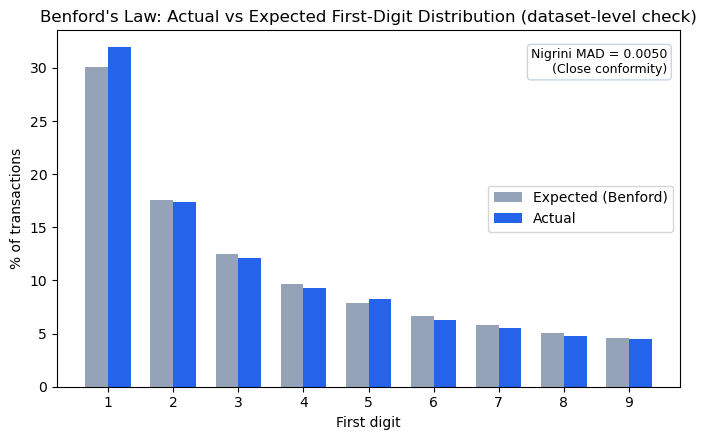

In [14]:
fig, ax = plt.subplots(figsize=(7, 4.5))
x = benford_table["digit"]
width = 0.35
ax.bar(x - width/2, benford_table["expected_pct"], width, label="Expected (Benford)", color="#94a3b8")
ax.bar(x + width/2, benford_table["actual_pct"], width, label="Actual", color="#2563eb")
ax.set_xlabel("First digit")
ax.set_ylabel("% of transactions")
ax.set_title("Benford's Law: Actual vs Expected First-Digit Distribution (dataset-level check)")
ax.set_xticks(x)
ax.legend()
ax.text(0.98, 0.95, f"Nigrini MAD = {mad:.4f}\n({verdict})", transform=ax.transAxes,
        ha="right", va="top", fontsize=9, bbox=dict(boxstyle="round", fc="white", ec="#cbd5e1"))
plt.tight_layout()
plt.savefig("benford_chart.png", dpi=150)
plt.show()

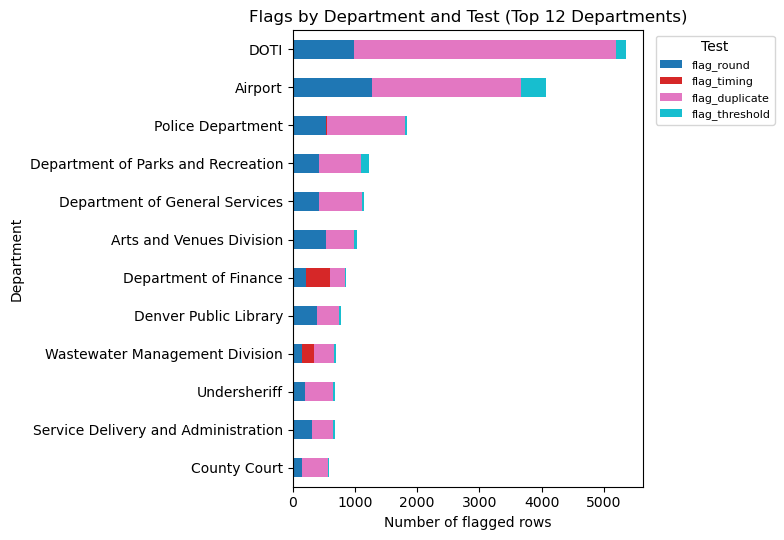

In [15]:
dept_flags = work.groupby("Department")[flag_cols].sum()
dept_flags["total"] = dept_flags.sum(axis=1)
top_depts = dept_flags.sort_values("total", ascending=False).head(12).drop(columns="total")

fig, ax = plt.subplots(figsize=(8, 5.5))
top_depts.plot(kind="barh", stacked=True, ax=ax, colormap="tab10")
ax.set_xlabel("Number of flagged rows")
ax.set_title("Flags by Department and Test (Top 12 Departments)")
ax.invert_yaxis()
ax.legend(title="Test", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig("flags_by_department.png", dpi=150)
plt.show()

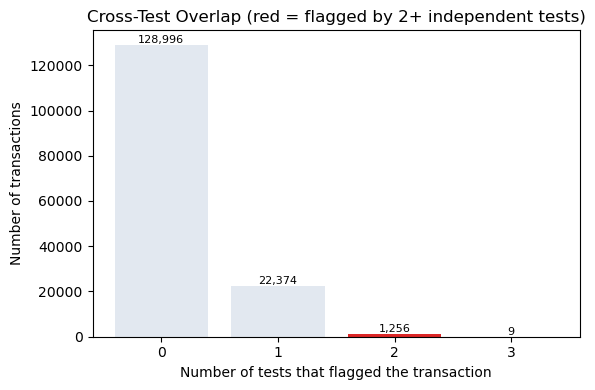

In [16]:
fig, ax = plt.subplots(figsize=(6, 4))
counts = work["n_tests_flagged"].value_counts().sort_index()
colors = ["#e2e8f0" if n < 2 else "#dc2626" for n in counts.index]
ax.bar(counts.index.astype(str), counts.values, color=colors)
ax.set_xlabel("Number of tests that flagged the transaction")
ax.set_ylabel("Number of transactions")
ax.set_title("Cross-Test Overlap (red = flagged by 2+ independent tests)")
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.savefig("overlap_chart.png", dpi=150)
plt.show()